# Notebook 03: Two-Zone Leptonic Model — MG3 J163554+3629

**Object:** MG3 J163554+3629 (z = 3.648)
**Depends on:** `../../data/SED.txt` only — builds everything from scratch like the original notebook.

**Structure:**
- Part 1: Data loading + Zone 1 prefit
- Part 2: Zone 2 + composite two-zone model
- Part 3: Minuit fit of composite model

**Key fix applied:** R dependency (`R = R_H * tan(theta_open)`) is built fresh each run.
The covariance matrix patch is applied before Minuit to prevent crashes.

**Outputs saved to `../../results/`:**
- `models/zone1_jet.pkl`
- `models/sed_data_binned_2zone.pkl`
- `models/twozone_prefit.pkl`
- `models/twozone_minuit.pkl`
- `plots/twozone_prefit_sed.png`
- `plots/twozone_minuit_sed.png`

---
## Part 1: Data loading + Zone 1 prefit

In [1]:
import jetset
print('JetSeT version:', jetset.__version__)

import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
import dill
%matplotlib inline

from jetset.data_loader import Data, ObsData
from jetset.sed_shaper import SEDShape
from jetset.jet_model import Jet
from jetset.obs_constrain import ObsConstrain
from jetset.model_manager import FitModel
from jetset.template_2Dmodel import EBLAbsorptionTemplate
from jetset.minimizer import ModelMinimizer, Minimizer

import os
os.makedirs('../../results/models', exist_ok=True)
os.makedirs('../../results/plots',  exist_ok=True)

# ============================================================
# Patch Minimizer.corr to handle degenerate covariance matrix
# (same fix as notebook 02 — prevents crashes when params hit boundaries)
# ============================================================
def _safe_corr(self):
    if self.covar is None:
        return None
    cov = np.asarray(self.covar)
    if cov.ndim != 2 or cov.shape[0] != cov.shape[1]:
        print('>>> WARNING: covariance matrix malformed -- skipping correlation matrix.')
        return None
    v = np.sqrt(np.diag(cov))
    outer_v = np.outer(v, v)
    correlation = cov / outer_v
    correlation[cov == 0] = 0
    return correlation

Minimizer.corr = property(_safe_corr)
print('Minimizer patched.')

JetSeT version: 1.3.0
Minimizer patched.


---> excluding  data_set/s ['-1']
filter -1 45
current datasets
dataset 0.0
---> data sets left after filtering None
---> data len after filtering=45

***  binning data  ***
---> N bins= 113
---> bin_widht= 0.15

Data points loaded: 45 raw, 28 binned


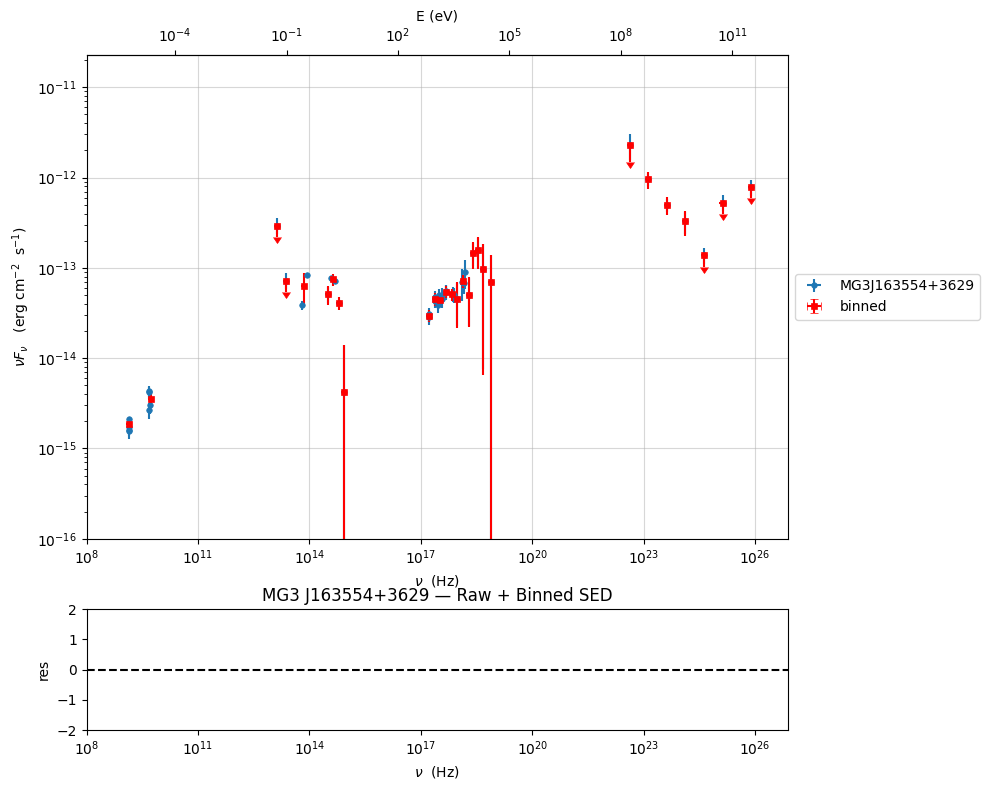

In [2]:
# ============================================================
# LOAD DATA — build from scratch, do NOT load from pkl
# (avoids R dependency corruption issues)
# ============================================================
d = np.genfromtxt('../../data/SED.txt')
d = d[d[:, 0] != 1.709E22]

data = Data(n_rows=d.shape[0])
data.set_field('x', d[:, 0])
data.set_field('y', d[:, 1])
data.set_field('dy', d[:, 2])

data.set_meta_data('z',          3.647763)
data.set_meta_data('UL_CL',      0.95)
data.set_meta_data('restframe',  'obs')
data.set_meta_data('data_scale', 'lin-lin')
data.set_meta_data('obj_name',   'MG3J163554+3629')

raw_data = ObsData(data_table=data)
sed_data = ObsData(data_table=data)

UL_freq = [1.324e25, 7.646e25, 4.188e24, 4.188e22, 2.417e13, 1.318e13]

# BINNED version for 2-zone (same as original notebook)
sed_data.filter_data_set('-1', exclude=True)
sed_data.group_data(bin_width=0.15)
sed_data.add_systematics(0.15, [10.**6, 10.**29])
for freq in UL_freq:
    mask = np.isclose(sed_data.table['nu_data'], freq, rtol=0.05)
    sed_data.table['UL'][mask] = True

print(f'Data points loaded: {d.shape[0]} raw, {len(sed_data.table)} binned')

myPlot = raw_data.plot_sed()
myPlot.add_data_plot(sed_data, label='binned', color='red', fmt='s', ms=5, mew=0.5)
myPlot.setlim(y_min=1E-16, x_min=1E8)
plt.title('MG3 J163554+3629 — Raw + Binned SED')
plt.show()


*** evaluating spectral indices for data ***


*** Log-Polynomial fitting of the synchrotron component ***
---> first blind fit run,  fit range: [9, 16]
--> class:  LSP

--> class:  LSP




model name,name,val,bestfit val,err +,err -,start val,fit range min,fit range max,frozen
LogParabolaEp,b,-7.549190e-02,-7.549190e-02,2.383978e-02,--,-6.619611e-02,-1.000000e+01,0.000000e+00,False
LogParabolaEp,Ep,1.336731e+01,1.336731e+01,6.073968e-01,--,1.394930e+01,0.000000e+00,3.000000e+01,False
LogParabolaEp,Sp,-1.340772e+01,-1.340772e+01,9.874369e-02,--,-1.322685e+01,-3.000000e+01,0.000000e+00,False
BBB,nuFnu_p_BBB,-1.358304e+01,-1.358304e+01,1.712940e-01,--,-1.322685e+01,-1.522685e+01,-1.122685e+01,False
BBB,nu_scale,5.027450e-03,5.027450e-03,1.147449e-02,--,0.000000e+00,-5.000000e-01,5.000000e-01,False


---> sync       nu_p=+1.336731e+01 (err=+6.073968e-01)  nuFnu_p=-1.340772e+01 (err=+9.874369e-02) curv.=-7.549190e-02 (err=+2.383978e-02)


*** Log-Polynomial fitting of the IC component ***
---> fit range: [16, 26]
---> LogCubic fit
====> simplex
====> migrad
====> simplex
====> migrad
====> simplex
====> migrad




model name,name,val,bestfit val,err +,err -,start val,fit range min,fit range max,frozen
LogCubic,b,-1.356107e-01,-1.356107e-01,2.115663e-02,--,-1.000000e+00,-1.000000e+01,0.000000e+00,False
LogCubic,c,-1.384093e-02,-1.384093e-02,3.841732e-03,--,-1.000000e+00,-1.000000e+01,1.000000e+01,False
LogCubic,Ep,2.205117e+01,2.205117e+01,1.210211e-01,--,2.307182e+01,0.000000e+00,3.000000e+01,False
LogCubic,Sp,-1.186701e+01,-1.186701e+01,1.074619e-01,--,-1.000000e+01,-3.000000e+01,0.000000e+00,False


---> IC         nu_p=+2.205117e+01 (err=+1.210211e-01)  nuFnu_p=-1.186701e+01 (err=+1.074619e-01) curv.=-1.356107e-01 (err=+2.115663e-02)



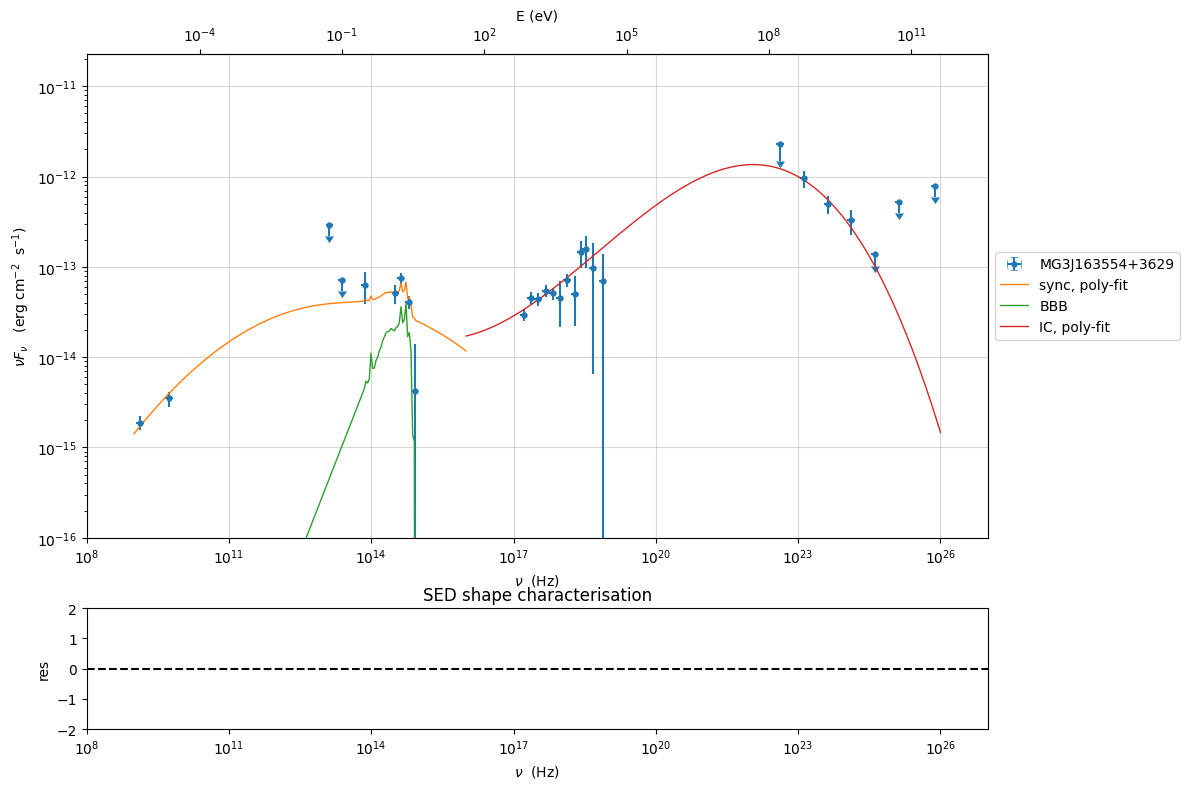

>>> SEDShape complete.


In [3]:
# SED shape characterisation
my_shape = SEDShape(sed_data)
my_shape.eval_indices(silent=True)

my_shape.sync_fit(check_BBB_template=True, check_host_gal_template=False,
                   use_log_par=True, minimizer='lsb', fit_range=[9,16], silent=True)
my_shape.IC_fit(fit_range=[16,26], minimizer='minuit', silent=True)

p = my_shape.plot_shape_fit()
p.setlim(y_min=1E-16)
plt.title('SED shape characterisation')
plt.show()
print('>>> SEDShape complete.')


***  constrains parameters from observable ***

===> setting C threads to 8
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,R,region_size,cm,7.693410e+16,1.000000e+03,1.000000e+30,False,False
jet_leptonic,R_H,region_position,cm,1.500000e+18,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,4.317927e-02,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,theta,jet-viewing-angle,deg,3.000000e+00,0.000000e+00,9.000000e+01,False,False
jet_leptonic,BulkFactor,jet-bulk-factor,lorentz-factor*,1.850000e+01,1.000000e+00,1.000000e+05,False,False
jet_leptonic,z_cosm,redshift,,3.647763e+00,0.000000e+00,--,False,False
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,3.902987e+01,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,3.568620e+04,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,2.549293e+02,0.000000e+00,--,False,False




adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
Zone 1: R_H  = 1.500e+18 cm
Zone 1: R    = 7.861e+16 cm  (should be ~7.85e16)
Zone 1: R_DT = 2.515e+19 cm
Zone 1: delta = 18.559


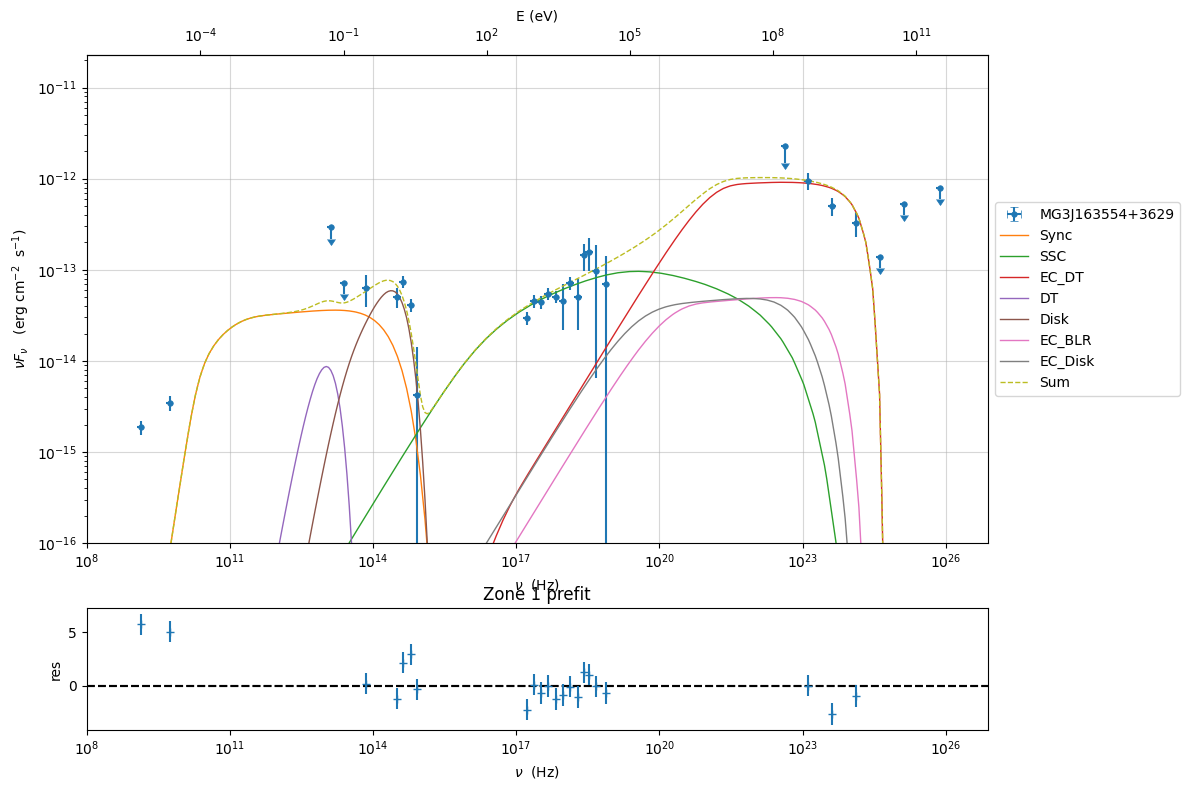

>>> Zone 1 complete.


In [4]:
# ============================================================
# ZONE 1 (compact): SSC + EC (BLR, Disk, DT)
# Location: between BLR and dust torus
# ============================================================
sed_obspar = ObsConstrain(
    theta=3, bulk_factor=18.5, B_range=[0.02,0.08],
    distr_e='bkn', t_var_sec=7*86400, nu_cut_IR=1E9,
    SEDShape=my_shape
)

zone1_jet = sed_obspar.constrain_SSC_EC_model(
    electron_distribution_log_values=False,
    EC_components_list=['EC_DT','EC_BLR','EC_Disk'],
    R_H=1.5E18, disk_type='MultiBB', silent=True
)

# Central engine
zone1_jet.set_par('L_Disk',   val=1.5817e46)
zone1_jet.set_par('M_BH',     val=1.9077e9)
zone1_jet.set_par('accr_eff', val=0.083)
zone1_jet.set_par('T_DT',     val=600.9)
zone1_jet.set_par('tau_DT',   val=0.1)
zone1_jet.set_par('tau_BLR',  val=0.1)

# Electron distribution refined values
zone1_jet.parameters.p.val           = 1.3
zone1_jet.parameters.p_1.val         = 2.9
zone1_jet.parameters.gamma_break.val = 400.0
zone1_jet.parameters.N.val           = 1000.0
zone1_jet.parameters.B.val           = 0.05
zone1_jet.parameters.gmin.val        = 2.0
zone1_jet.parameters.gmax.val        = 16000.0
zone1_jet.parameters.theta.val       = 3.0
zone1_jet.parameters.BulkFactor.val  = 15.0
zone1_jet.parameters.R_inner_Sw.val  = 10.1
zone1_jet.parameters.R_ext_Sw.val    = 846.0

# ============================================================
# ADD R <-> R_H DEPENDENCY
# Set R_H = 1.5e18 FIRST, then add dependency
# Do NOT recompute R_H from target_R (causes wrong value)
# ============================================================
zone1_jet.parameters.R_H.val = 1.5e18
zone1_jet.add_user_par(name='theta_open', val=3, units='deg')
zone1_jet.make_dependent_par(
    par='R', depends_on=['R_H','theta_open'],
    par_expr='np.tan(np.radians(theta_open))*R_H'
)
zone1_jet.eval()

# Verify
print(f'Zone 1: R_H  = {zone1_jet.parameters.R_H.val:.3e} cm')
print(f'Zone 1: R    = {zone1_jet.parameters.R.val:.3e} cm  (should be ~7.85e16)')
print(f'Zone 1: R_DT = {zone1_jet.parameters.R_DT.val:.3e} cm')
print(f'Zone 1: delta = {zone1_jet.get_beaming():.3f}')
assert zone1_jet.parameters.R.val > 0, 'ERROR: R is negative!'

p = zone1_jet.plot_model(sed_data=sed_data)
p.add_residual_plot(zone1_jet, sed_data)
p.setlim(y_min=1E-16, x_min=1E8)
plt.title('Zone 1 prefit')
plt.show()
print('>>> Zone 1 complete.')

---
## Part 2: Zone 2 + composite two-zone model

Zone 2 is placed at 5 × R_DT — outside the dust torus. EC components are switched off.
Sync + SSC only contribute from Zone 2.

In [5]:
# ============================================================
# ZONE 2 (extended): Sync + SSC only, outside R_DT
# ============================================================
zone2_jet = Jet(
    name='jet_extended',
    electron_distribution='bkn',
    electron_distribution_log_values=False,
    beaming_expr='bulk_theta'
)

# Add EC machinery for parameter linking — EC emission turned off below
zone2_jet.add_EC_component(
    EC_components_list=['EC_DT','EC_BLR','EC_Disk'],
    disk_type='MultiBB'
)

# Shared central engine parameters
for par_name in ['z_cosm','L_Disk','M_BH','accr_eff','R_inner_Sw','R_ext_Sw',
                  'T_DT','tau_DT','tau_BLR','theta','BulkFactor']:
    zone2_jet.set_par(par_name, val=zone1_jet.parameters.get_par_by_name(par_name).val)

# R <-> R_H dependency for Zone 2 (same opening angle)
zone2_jet.add_user_par(name='theta_open', val=3, units='deg')
zone2_jet.make_dependent_par(
    par='R', depends_on=['R_H','theta_open'],
    par_expr='np.tan(np.radians(theta_open))*R_H'
)

# Place Zone 2 at 5 x R_DT
R_DT_z1 = zone1_jet.parameters.R_DT.val
R_H2 = 5.0 * R_DT_z1
zone2_jet.set_par('R_H', val=R_H2)

# Electron distribution: same shape, lower N and B
zone2_jet.set_par('p',           val=zone1_jet.parameters.p.val)
zone2_jet.set_par('p_1',         val=zone1_jet.parameters.p_1.val)
zone2_jet.set_par('gamma_break', val=zone1_jet.parameters.gamma_break.val)
zone2_jet.set_par('gmin',        val=zone1_jet.parameters.gmin.val)
zone2_jet.set_par('gmax',        val=zone1_jet.parameters.gmax.val)
zone2_jet.set_par('B',           val=zone1_jet.parameters.B.val / 10.0)
zone2_jet.set_par('N',           val=zone1_jet.parameters.N.val * 1e-4)

# Turn OFF EC for Zone 2
zone2_jet.spectral_components.EC_DT.state  = 'off'
zone2_jet.spectral_components.EC_BLR.state = 'off'
zone2_jet.spectral_components.EC_Disk.state = 'off'
zone2_jet.spectral_components.DT.state     = 'off'
zone2_jet.spectral_components.Disk.state   = 'off'

zone2_jet.eval()

print(f'Zone 2: R_H = {zone2_jet.parameters.R_H.val:.3e} cm  (> R_DT = {R_DT_z1:.3e} cm)')
print(f'Zone 2: R   = {zone2_jet.parameters.R.val:.3e} cm')
print(f'Zone 2: B   = {zone2_jet.parameters.B.val:.4f} G')
print(f'Zone 2: N   = {zone2_jet.parameters.N.val:.3e}')
assert zone2_jet.parameters.R.val > 0, 'ERROR: Zone 2 R is negative!'
print('>>> Zone 2 complete.')

===> setting C threads to 8
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
Zone 2: R_H = 1.258e+20 cm  (> R_DT = 2.515e+19 cm)
Zone 2: R   = 6.591e+18 cm
Zone 2: B   = 0.0050 G
Zone 2: N   = 1.000e-01
>>> Zone 2 complete.


adding par: z_cosm to  z_cosm
adding par: theta to  theta
adding par: BulkFactor to  BulkFactor
adding par: theta_open to  theta_open
adding par: L_Disk to  L_Disk
adding par: M_BH to  M_BH
adding par: accr_eff to  accr_eff
adding par: T_DT to  T_DT
adding par: tau_DT to  tau_DT
adding par: tau_BLR to  tau_BLR
adding par: R_inner_Sw to  R_inner_Sw
adding par: R_ext_Sw to  R_ext_Sw
adding par: z_cosm to  z_cosm
>>> Composite two-zone model assembled.

--------------------------------------------------------------------------------
Composite model description
--------------------------------------------------------------------------------
name: TwoZone_Model  
type: composite_model  
components models:
 -model name: jet_leptonic model type: jet
 -model name: jet_extended model type: jet
 -model name: Franceschini_2008 model type: table2D

--------------------------------------------------------------------------------
individual component description

------------------------------------

model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,"*R(D,theta_open)",region_size,cm,7.861167e+16,1.000000e+03,1.000000e+30,False,True
jet_leptonic,R_H(M),region_position,cm,1.500000e+18,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,5.000000e-02,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,theta(M),jet-viewing-angle,deg,3.000000e+00,0.000000e+00,9.000000e+01,False,False
jet_leptonic,BulkFactor(M),jet-bulk-factor,lorentz-factor*,1.500000e+01,1.000000e+00,1.000000e+05,False,False
jet_leptonic,z_cosm(M),redshift,,3.647763e+00,0.000000e+00,--,False,False
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,2.000000e+00,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,1.600000e+04,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,1.000000e+03,0.000000e+00,--,False,False


--------------------------------------------------------------------------------

--------------------------------------------------------------------------------
model description: 
--------------------------------------------------------------------------------
type: Jet
name: jet_extended  
geometry: spherical  

electrons distribution:
 type: bkn  
 gamma energy grid size:  201
 gmin grid : 2.000000e+00
 gmax grid : 1.600000e+04
 normalization:  True
 log-values:  False
 ratio of cold protons to relativistic electrons: 1.000000e+00

accretion disk:
 disk Type: MultiBB
 L disk: 1.581700e+46 (erg/s)
 T disk: 2.199208e+04 (K)
 nu peak disk: 1.797151e+15 (Hz)
 Sw radius 5.634467e+14 (cm)
 L Edd. 2.480010e+47 (erg/s)
 accr_rate: 3.361849e+00 (M_sun/yr)
 accr_rate Edd.: 5.271176e+01 (M_sun/yr)
radiative fields:
 seed photons grid size:  100
 IC emission grid size:  100
 source emissivity lower bound :  1.000000e-120
 spectral components:
   name:Sum, state: on
   name:Sum, hidden: False


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_extended,"*R(D,theta_open)",region_size,cm,6.591099e+18,1.000000e+03,1.000000e+30,False,True
jet_extended,R_H(M),region_position,cm,1.257657e+20,0.000000e+00,--,False,True
jet_extended,B,magnetic_field,gauss,5.000000e-03,0.000000e+00,--,False,False
jet_extended,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_extended,"theta(L,jet_leptonic)",jet-viewing-angle,deg,--,--,--,False,True
jet_extended,"BulkFactor(L,jet_leptonic)",jet-bulk-factor,lorentz-factor*,--,--,--,False,True
jet_extended,"z_cosm(L,jet_leptonic)",redshift,,--,--,--,False,True
jet_extended,gmin,low-energy-cut-off,lorentz-factor*,2.000000e+00,1.000000e+00,1.000000e+09,False,False
jet_extended,gmax,high-energy-cut-off,lorentz-factor*,1.600000e+04,1.000000e+00,1.000000e+15,False,False
jet_extended,N,emitters_density,1 / cm3,1.000000e-01,0.000000e+00,--,False,False


--------------------------------------------------------------------------------

--------------------------------------------------------------------------------
model description
--------------------------------------------------------------------------------
name: Franceschini_2008  
type: table2D  

--------------------------------------------------------------------------------


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
Franceschini_2008,scale_factor,scale_factor,,1.000000e+00,0.000000e+00,--,False,True
Franceschini_2008,"z_cosm(L,jet_leptonic)",redshift,,--,--,--,False,True


--------------------------------------------------------------------------------
--------------------------------------------------------------------------------


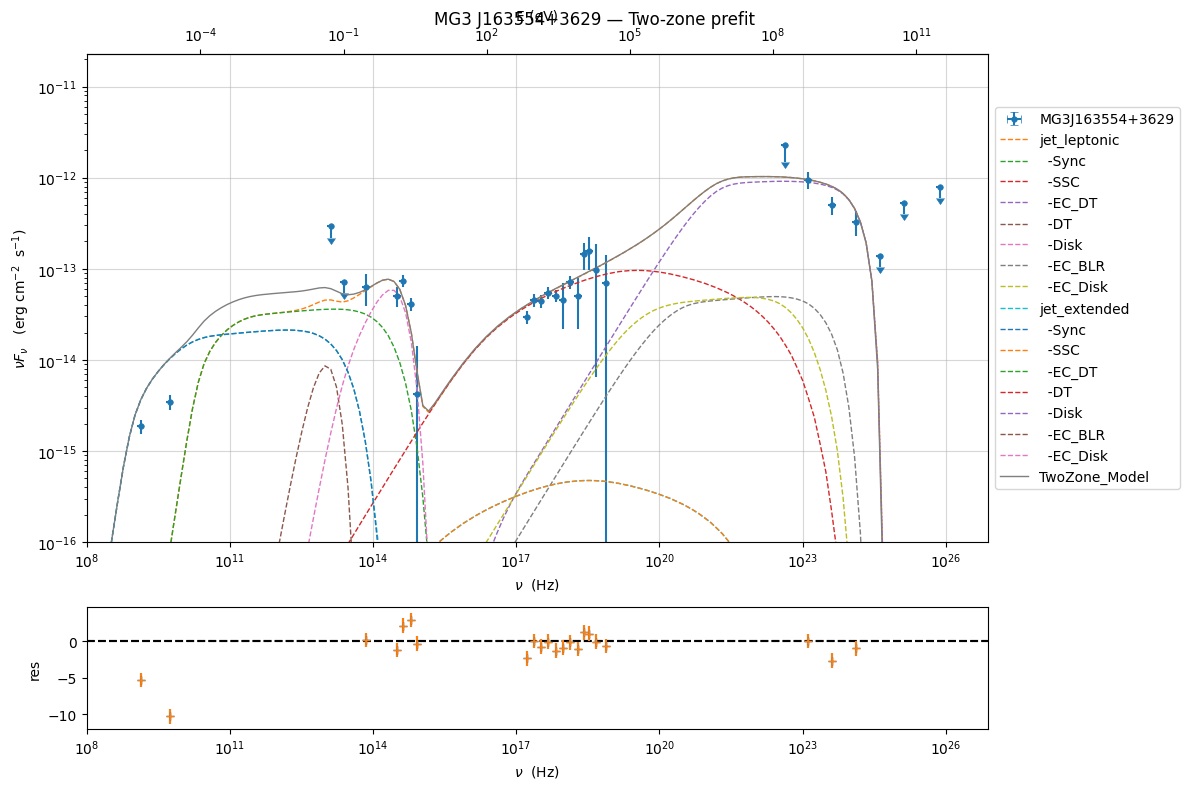

Saved: twozone_prefit.pkl, sed_data_binned_2zone.pkl


In [6]:
# ============================================================
# COMPOSITE MODEL: Zone1 + Zone2 + EBL
# ============================================================
composite_jet = FitModel(jet=zone1_jet, name='TwoZone_Model')
composite_jet.add_component(zone2_jet)

ebl = EBLAbsorptionTemplate.from_name('Franceschini_2008')
composite_jet.add_component(ebl)

# Link shared parameters: jet_extended follows jet_leptonic
linked_pars = ['z_cosm','theta','BulkFactor','theta_open',
               'L_Disk','M_BH','accr_eff',
               'T_DT','tau_DT','tau_BLR',
               'R_inner_Sw','R_ext_Sw']
for par in linked_pars:
    try:
        composite_jet.link_par(par_name=par,
                                from_model='jet_extended',
                                to_model='jet_leptonic')
    except Exception as e:
        print(f'  Could not link {par}: {e}')

composite_jet.link_par(par_name='z_cosm',
                        from_model='Franceschini_2008',
                        to_model='jet_leptonic')

composite_jet.composite_expr = '(jet_leptonic + jet_extended) * Franceschini_2008'
composite_jet.eval()

print('>>> Composite two-zone model assembled.')
composite_jet.show_model()

p = composite_jet.plot_model(sed_data=sed_data)
p.add_residual_plot(composite_jet, sed_data)
p.setlim(y_min=1E-16, x_min=1E8)
plt.suptitle('MG3 J163554+3629 — Two-zone prefit')
plt.savefig('../../results/plots/twozone_prefit_sed.png', dpi=150, bbox_inches='tight')
plt.show()

# Save prefit
composite_jet.save_model('../../results/models/twozone_prefit.pkl')
sed_data.save('../../results/models/sed_data_binned_2zone.pkl')
print('Saved: twozone_prefit.pkl, sed_data_binned_2zone.pkl')

---
## Part 3: Minuit fit of the two-zone composite model

We rebuild the model fresh from scratch here too — do NOT load from pkl.
This avoids the R dependency corruption that occurs on pkl reload.

In [7]:
# ============================================================
# FREEZE / FREE SETUP FOR MINUIT
# ============================================================
composite_jet.jet_leptonic.set_num_c_threads(8)
composite_jet.jet_extended.set_num_c_threads(8)

# Zone 1 freeze
composite_jet.freeze('jet_leptonic', 'theta')
composite_jet.freeze('jet_leptonic', 'theta_open')
composite_jet.freeze('jet_leptonic', 'gmax')
composite_jet.freeze('jet_leptonic', 'z_cosm')
composite_jet.freeze('jet_leptonic', 'accr_eff')
composite_jet.freeze('jet_leptonic', 'tau_DT')
composite_jet.freeze('jet_leptonic', 'tau_BLR')

# Zone 1 free
composite_jet.free('jet_leptonic', 'R_H')
composite_jet.free('jet_leptonic', 'B')
composite_jet.free('jet_leptonic', 'BulkFactor')
composite_jet.free('jet_leptonic', 'N')
composite_jet.free('jet_leptonic', 'gamma_break')
composite_jet.free('jet_leptonic', 'p')
composite_jet.free('jet_leptonic', 'p_1')
composite_jet.free('jet_leptonic', 'R_inner_Sw')
composite_jet.free('jet_leptonic', 'R_ext_Sw')
composite_jet.free('jet_leptonic', 'M_BH')
composite_jet.free('jet_leptonic', 'T_DT')
composite_jet.free('jet_leptonic', 'L_Disk')
composite_jet.free('jet_leptonic', 'gmin')

# Zone 1 fit ranges
composite_jet.jet_leptonic.parameters.R_H.fit_range        = [5.0e+17, 3.0e+18]
composite_jet.jet_leptonic.parameters.B.fit_range          = [0.010,   0.100]
composite_jet.jet_leptonic.parameters.BulkFactor.fit_range = [10.0,    25.0]
composite_jet.jet_leptonic.parameters.N.fit_range          = [4.0e+02, 2.0e+03]
composite_jet.jet_leptonic.parameters.gamma_break.fit_range= [2.0e+02, 3.0e+03]
composite_jet.jet_leptonic.parameters.p.fit_range          = [1.00,    1.80]
composite_jet.jet_leptonic.parameters.p_1.fit_range        = [2.50,    3.80]
composite_jet.jet_leptonic.parameters.R_inner_Sw.fit_range = [3.0,     1.5e+01]
composite_jet.jet_leptonic.parameters.R_ext_Sw.fit_range   = [5.0e+01, 5.0e+03]
composite_jet.jet_leptonic.parameters.M_BH.fit_range       = [5.0e+08, 2.0e+09]
composite_jet.jet_leptonic.parameters.T_DT.fit_range       = [1.0e+02, 1.0e+03]
composite_jet.jet_leptonic.parameters.L_Disk.fit_range     = [1.0e+46, 5.0e+46]
composite_jet.jet_leptonic.parameters.gmin.fit_range       = [1.0,     50.0]

# Zone 2 freeze
composite_jet.freeze('jet_extended', 'gmin')
composite_jet.freeze('jet_extended', 'gmax')
composite_jet.freeze('jet_extended', 'p')
composite_jet.freeze('jet_extended', 'p_1')
composite_jet.freeze('jet_extended', 'gamma_break')

# Zone 2 free
composite_jet.free('jet_extended', 'N')
composite_jet.free('jet_extended', 'B')

# Zone 2 fit ranges
composite_jet.jet_extended.parameters.N.fit_range = [1.0e-03, 1.0e+01]
composite_jet.jet_extended.parameters.B.fit_range = [1.0e-04, 5.0e-02]

print('>>> Freeze/free configured. Running Minuit...')

===> setting C threads to 8
===> setting C threads to 8
>>> Freeze/free configured. Running Minuit...


filtering data in fit range = [1.000000e+08,1.000000e+30]
data length 28

*** start fit process ***
----- 


0it [00:00, ?it/s]

====> simplex
====> migrad
>>> WARNING: covariance matrix malformed -- skipping correlation matrix.
- best chisq=1.67216e+01

-------------------------------------------------------------------------
Fit report

Model: TwoZone_Sum


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,"*R(D,theta_open)",region_size,cm,8.669693e+16,1.000000e+03,1.000000e+30,False,True
jet_leptonic,R_H(M),region_position,cm,1.654276e+18,0.000000e+00,--,False,False
jet_leptonic,B,magnetic_field,gauss,3.364436e-02,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,theta(M),jet-viewing-angle,deg,3.000000e+00,0.000000e+00,9.000000e+01,False,True
jet_leptonic,BulkFactor(M),jet-bulk-factor,lorentz-factor*,1.049204e+01,1.000000e+00,1.000000e+05,False,False
jet_leptonic,z_cosm(M),redshift,,3.647763e+00,0.000000e+00,--,False,True
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,2.636083e+00,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,1.600000e+04,1.000000e+00,1.000000e+15,False,True
jet_leptonic,N,emitters_density,1 / cm3,1.050346e+03,0.000000e+00,--,False,False



converged=True
calls=2097
mesg=


...

--------------------------------------------------------------------------------

--------------------------------------------------------------------------------
model description: 
--------------------------------------------------------------------------------
type: Jet
name: jet_extended  
geometry: spherical  

electrons distribution:
 type: bkn  
 gamma energy grid size:  201
 gmin grid : 2.000000e+00
 gmax grid : 1.600000e+04
 normalization:  True
 log-values:  False
 ratio of cold protons to relativistic electrons: 1.000000e+00

accretion disk:
 disk Type: MultiBB
 L disk: 1.749714e+46 (erg/s)
 T disk: 2.831846e+04 (K)
 nu peak disk: 2.314131e+15 (Hz)
 Sw radius 5.801803e+14 (cm)
 L Edd. 2.553663e+47 (erg/s)
 accr_rate: 3.718957e+00 (M_sun/yr)
 accr_rate Edd.: 5.427723e+01 (M_sun/yr)
radiative fields:
 seed photons grid size:  100
 IC emission grid size:  100
 source emissivity lower bound :  1.000000e-120
 spectral components:
   name:Sum, state: on
   name:Sum, hidden: False


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_extended,"*R(D,theta_open)",region_size,cm,6.591099e+18,1.000000e+03,1.000000e+30,False,True
jet_extended,R_H(M),region_position,cm,1.257657e+20,0.000000e+00,--,False,True
jet_extended,B,magnetic_field,gauss,3.242850e-03,0.000000e+00,--,False,False
jet_extended,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_extended,"theta(L,jet_leptonic)",jet-viewing-angle,deg,--,--,--,False,True
jet_extended,"BulkFactor(L,jet_leptonic)",jet-bulk-factor,lorentz-factor*,--,--,--,False,True
jet_extended,"z_cosm(L,jet_leptonic)",redshift,,--,--,--,False,True
jet_extended,gmin,low-energy-cut-off,lorentz-factor*,2.000000e+00,1.000000e+00,1.000000e+09,False,True
jet_extended,gmax,high-energy-cut-off,lorentz-factor*,1.600000e+04,1.000000e+00,1.000000e+15,False,True
jet_extended,N,emitters_density,1 / cm3,1.172464e-01,0.000000e+00,--,False,False


--------------------------------------------------------------------------------

--------------------------------------------------------------------------------
model description
--------------------------------------------------------------------------------
name: Franceschini_2008  
type: table2D  

--------------------------------------------------------------------------------


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
Franceschini_2008,scale_factor,scale_factor,,1.000000e+00,0.000000e+00,--,False,True
Franceschini_2008,"z_cosm(L,jet_leptonic)",redshift,,--,--,--,False,True


--------------------------------------------------------------------------------
--------------------------------------------------------------------------------


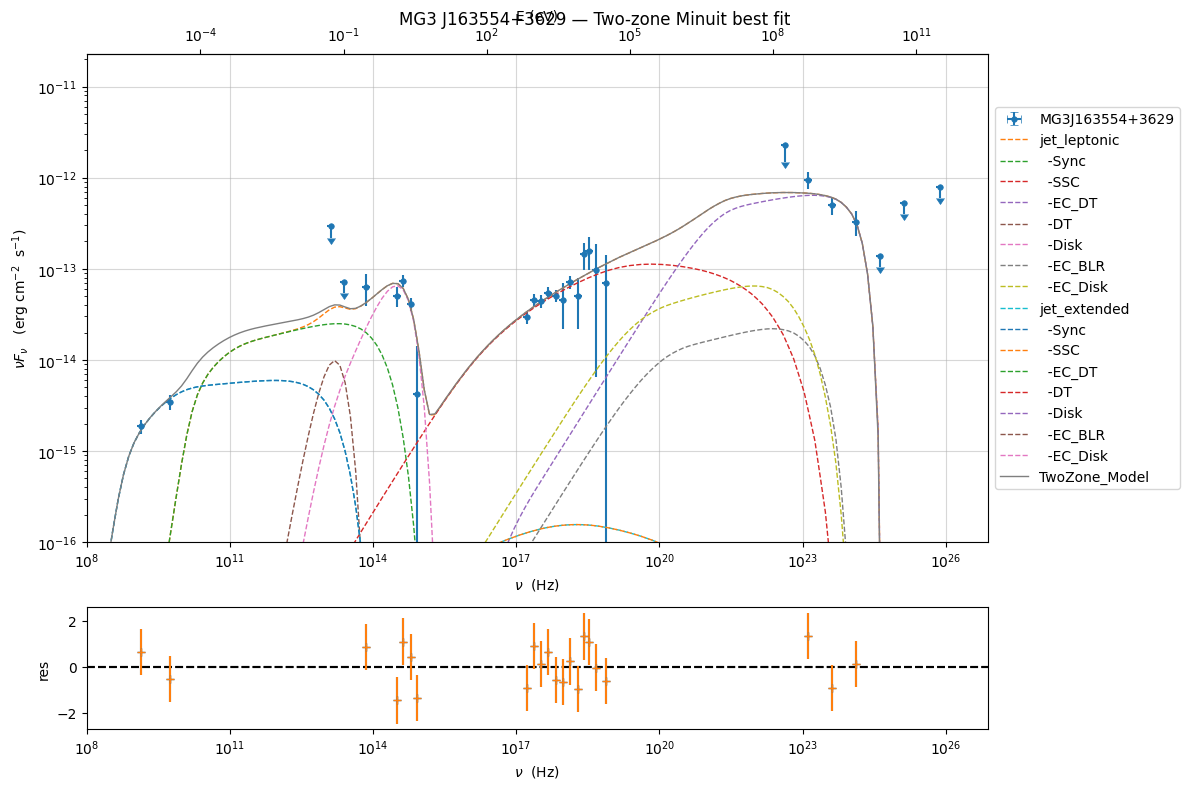

Zone 1 delta = 16.109
Zone 2 delta = 16.109
Saved: twozone_minuit.pkl, twozone_minimizer.pkl


In [8]:
# ============================================================
# RUN MINUIT
# ============================================================
model_minimizer = ModelMinimizer('minuit')
best_fit = model_minimizer.fit(
    composite_jet, sed_data,
    10**8., 10**30.,
    fitname='TwoZone_Sum',
    repeat=1,
    use_UL=True
)

composite_jet.eval()
composite_jet.save_model('../../results/models/twozone_minuit.pkl')
model_minimizer.save_model('../../results/models/twozone_minimizer.pkl')

print('\n=== Two-zone Minuit best-fit ===')
composite_jet.show_model()

p2 = composite_jet.plot_model(sed_data=sed_data)
p2.add_residual_plot(composite_jet, sed_data)
p2.setlim(y_min=1E-16, x_min=1E8)
plt.suptitle('MG3 J163554+3629 — Two-zone Minuit best fit')
plt.savefig('../../results/plots/twozone_minuit_sed.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Zone 1 delta = {composite_jet.jet_leptonic.get_beaming():.3f}')
print(f'Zone 2 delta = {composite_jet.jet_extended.get_beaming():.3f}')
print('Saved: twozone_minuit.pkl, twozone_minimizer.pkl')